# Margem de erro e tendência: o que os números sustentam

Este caderno responde: **as mudanças que vemos de um período legal para outro são reais ou podem ser sorte da amostra?**
Cada porcentagem ou média dos outros cadernos é uma estimativa feita com poucos ou muitos anúncios. Aqui damos a cada uma
uma **margem de erro** e testamos se há uma **tendência** ao longo dos quatro períodos, para 9 medidas fixas (a lista não muda
conforme o resultado, para não escolhermos só o que deu certo).

Corpus `corp3`, campos `c6`, temas `t5`. Os números dos comentários foram lidos da saída
da própria execução; se o banco mudar, **confira os números de novo**.

- **Intervalo de Wilson (proporções):** a faixa de valores plausíveis para a porcentagem verdadeira, dado quantos anúncios há no grupo; grupos pequenos têm faixas largas.
- **Bootstrap (médias e medianas):** sorteamos os anúncios do grupo, com reposição, 2000 vezes; a faixa é onde caem 95% dos resultados.
- **Tendência:** teste de Cochran–Armitage (proporções) ou correlação de Spearman (valores contínuos) entre a ordem do período e a medida; o p diz quão raro seria ver essa tendência só por acaso.
- **p ajustado (Benjamini–Hochberg):** como fazemos 9 testes, alguns passariam por sorte; o ajuste corrige isso.

> **Cuidado ao ler:** (1) os anúncios foram achados por **frases de busca**, não por sorteio: a margem de erro mede só o
> erro de amostragem *dentro do que a busca achou*, não o viés da busca. (2) **O bootstrap usa o modelo de temas fixo:** mede o erro de
> amostragem dos anúncios, **não a instabilidade do LDA** (outra semente poderia reorganizar os temas). (3) Células com
> **n < 30 vêm marcadas com ⚠**: a faixa é larga e frágil. (4) Os anúncios de um mesmo período não são independentes (reanúncios, mesmo dono), o que torna as faixas um pouco otimistas.

## Preparação: ler o corpus, os campos e os temas

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from hdb import config
from hdb.banco import BancoSupabase
from hdb.categorias import categorias
from hdb.estatistica import bootstrap_ic, cochran_armitage, diferenca_ic, fdr_bh, spearman_tendencia, wilson
from hdb.topicos import nomear

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
banco = BancoSupabase()
db = banco.cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]
MIN_N = 30
MODELO = config.VERSAO_TOPICOS

corpus = pd.DataFrame(banco.anuncios_do_corpus(config.VERSAO_CORPUS))
corpus = corpus[corpus["texto_padrao"].fillna("").str.strip() != ""][["id", "periodo_legal"]]
# campos e texto ORIGINAL (para as marcas no corpo), da view anuncios_completos
extra = ler_tudo(lambda: db.table("anuncios_completos")
                 .select("id,texto,c_tipo,c_sexo,c_idade_min,c_idade_max,c_nacoes,c_recompensa")
                 .in_("versao", list(config.VERSOES_ANUNCIOS)).eq("c_versao", config.VERSAO_CAMPOS).order("id")).drop_duplicates("id")
df = corpus.merge(extra, on="id", how="left")
df["periodo"] = df["periodo_legal"].map(lambda p: periodo_curto(p) if isinstance(p, str) else None)
df = df[df["periodo"].isin(PERIODOS)].copy()
df["idade"] = df[["c_idade_min", "c_idade_max"]].astype(float).mean(axis=1)
tem = lambda s: s.map(lambda v: isinstance(v, list) and len(v) > 0)
print(f"{len(df)} anúncios no corpus {config.VERSAO_CORPUS} com período legal")
if len(df) != 2191:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2191 anúncios e agora são {len(df)}: "
          "confira os números dos textos antes de usar.")

# misturas de temas do modelo da rodada, com os nomes sugeridos (topicos.nomear sobre as 12 palavras de maior peso)
palavras = ler_tudo(lambda: db.table("topico_palavras").select("topico,palavra,peso").eq("versao", MODELO)
                    .order("topico").order("peso", desc=True))
dist = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao").eq("versao", MODELO)
                .order("anuncio_id").order("topico"))
NOMES = nomear({t: g.sort_values("peso", ascending=False)["palavra"].head(12) for t, g in palavras.groupby("topico")})
pivo = dist.pivot(index="anuncio_id", columns="topico", values="proporcao").rename(columns=NOMES)
temas = df.set_index("id")[["periodo"]].join(pivo, how="inner")
print(f"{len(temas)} anúncios com mistura de temas no modelo {MODELO}")
print("Temas:", "; ".join(f"T{t} {n}" for t, n in NOMES.items()))

def soma_temas(predicado):
    cols = [n for n in pivo.columns if predicado(n)]
    return temas[cols].sum(axis=1) if cols else None   # None = tema ausente neste modelo

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
COR = "#0072B2"

2191 anúncios no corpus corp3 com período legal


2191 anúncios com mistura de temas no modelo t5
Temas: T0 Aluguel de pretos e moleques para todo o serviço; T1 Fuga: nome, idade e dono; T2 Venda com preço e qualidades; T3 Mulheres: lavar, engomar, cozinhar (aluguel e venda); T4 Fuga: roupa levada e nação; T5 Ama de leite


## 1. As 9 medidas
Cada medida tem seu grupo (quem entra no denominador) e seu tipo: **proporção** (Wilson; tendência de Cochran–Armitage)
ou **contínua** (bootstrap; tendência de Spearman sobre a ordem do período, anúncio a anúncio).
1. % de anúncios que são **fuga** (todo o corpus). 2. % de fugas **com recompensa**. 3. % de fugas **com nação**.
4. % de fugas **com marcas no corpo** (texto original). 5. **idade mediana** dos fugidos. 6. **% feminino nos aluguéis**
(entre os que dizem o sexo). 7. **parcela dos temas de fuga** somados. 8. **parcela dos temas de serviço doméstico** somados.
9. **parcela do tema "Ama de leite"**.

In [2]:
fuga = df[df["c_tipo"] == "fuga"]
alug = df[(df["c_tipo"] == "aluguel") & df["c_sexo"].isin(["f", "m"])]
marcas = fuga["texto"].map(lambda t: len(categorias(t)["marcas"]) > 0 if isinstance(t, str) else False)

def _g(base, serie):  # DataFrame (periodo, v) ou None
    return pd.DataFrame({"periodo": base["periodo"], "v": serie.astype(float)}).dropna()

def _tema(serie):
    return None if serie is None else pd.DataFrame({"periodo": temas["periodo"], "v": serie.astype(float)})

# (nome, tipo, unidade, dados)
MEDIDAS = [
    ("1. % de anúncios que são fuga", "prop", "%", _g(df, df["c_tipo"] == "fuga")),
    ("2. % de fugas com recompensa", "prop", "%", _g(fuga, fuga["c_recompensa"].fillna(False).astype(bool))),
    ("3. % de fugas com nação", "prop", "%", _g(fuga, tem(fuga["c_nacoes"]))),
    ("4. % de fugas com marcas no corpo", "prop", "%", _g(fuga, marcas)),
    ("5. Idade mediana dos fugidos (anos)", "mediana", "anos", _g(fuga, fuga["idade"])),
    ("6. % feminino nos aluguéis", "prop", "%", _g(alug, alug["c_sexo"] == "f")),
    ("7. Parcela dos temas de fuga (%)", "media", "%", _tema(soma_temas(lambda n: n.startswith("Fuga")))),
    ("8. Parcela dos temas de serviço doméstico (%)", "media", "%",
     _tema(soma_temas(lambda n: n.startswith("Mulheres: lavar") or n.startswith("Aluguel de pretos e moleques")))),
    ("9. Parcela do tema Ama de leite (%)", "media", "%", _tema(soma_temas(lambda n: n == "Ama de leite"))),
]
print(f"{len(MEDIDAS)} medidas; ausentes no modelo {MODELO}: {[m[0] for m in MEDIDAS if m[3] is None] or 'nenhuma'}")

9 medidas; ausentes no modelo t5: nenhuma


## 2. Cálculo: valor e margem de erro por período, tendência e diferença
Valor e IC de 95% por período; p de tendência; p ajustado (Benjamini–Hochberg sobre as 9 medidas); e a diferença do
último período com dados menos o primeiro, com IC por bootstrap.

In [3]:
FATOR = lambda tipo: 100 if tipo != "mediana" else 1   # proporções e parcelas em %, idade em anos
RES = {}
for nome, tipo, unidade, d in MEDIDAS:
    if d is None or d.empty:
        RES[nome] = None
        continue
    f = FATOR(tipo)
    por = {}
    for p in PERIODOS:
        v = d.loc[d["periodo"] == p, "v"].to_numpy()
        n = len(v)
        if tipo == "prop":
            est, lo, hi = wilson(int(v.sum()), n)
        elif n == 0:
            est = lo = hi = float("nan")
        else:
            est, lo, hi = bootstrap_ic(v, np.median if tipo == "mediana" else np.mean)
        por[p] = {"n": n, "valor": est * f, "baixo": lo * f, "alto": hi * f, "v": v}
    com_dados = [p for p in PERIODOS if por[p]["n"] > 0]
    if tipo == "prop":
        z, pval = cochran_armitage([int(por[p]["v"].sum()) for p in com_dados], [por[p]["n"] for p in com_dados])
        estat = np.mean
    else:
        ordem = d["periodo"].map(PERIODOS.index).to_numpy()
        _, pval = spearman_tendencia(ordem, d["v"].to_numpy())
        estat = np.median if tipo == "mediana" else np.mean
    prim, ult = (com_dados[0], com_dados[-1]) if len(com_dados) >= 2 else (None, None)
    if prim:
        dif, dlo, dhi = diferenca_ic(por[prim]["v"], por[ult]["v"], estat)
    else:
        dif = dlo = dhi = float("nan")
    RES[nome] = {"tipo": tipo, "unidade": unidade, "por": por, "p": pval, "prim": prim, "ult": ult,
                 "dif": dif * f, "dlo": dlo * f, "dhi": dhi * f}
nomes_ok = [m[0] for m in MEDIDAS]
padj = fdr_bh([RES[n]["p"] if RES[n] else float("nan") for n in nomes_ok])
for n, pa in zip(nomes_ok, padj):
    if RES[n]:
        RES[n]["padj"] = float(pa)

def veredito(r):
    if r is None:
        return "tema ausente"
    if r["prim"] is None or np.isnan(r["p"]):
        return "sem dados suficientes"
    if r["por"][r["prim"]]["n"] < MIN_N or r["por"][r["ult"]]["n"] < MIN_N:
        return "frágil (n<30)"
    if r["padj"] < 0.05 and not (r["dlo"] <= 0 <= r["dhi"]):
        return "sustenta"
    return "não sustenta"

nf = lambda x, c=1: "—" if x is None or np.isnan(x) else f"{x:.{c}f}".replace(".", ",")
def pf(x):
    return "—" if x is None or np.isnan(x) else ("<0,001" if x < 0.001 else f"{x:.3f}".replace(".", ","))
def cel(c):
    return f"{nf(c['valor'])} [{nf(c['baixo'])}; {nf(c['alto'])}]" + (" ⚠" if c["n"] < MIN_N else "")

linhas = []
for n in nomes_ok:
    r = RES[n]
    if r is None:
        linhas.append({"Medida": n, "1º período": "tema ausente", "Último período": "—", "Diferença [IC 95%]": "—",
                       "p": "—", "p ajustado": "—", "Tendência": "tema ausente"})
        continue
    a, b = r["por"].get(r["prim"]) if r["prim"] else None, r["por"].get(r["ult"]) if r["ult"] else None
    linhas.append({"Medida": n,
                   "1º período": f"{r['prim']}: {nf(a['valor'])} (n={a['n']}{' ⚠' if a['n'] < MIN_N else ''})" if a else "—",
                   "Último período": f"{r['ult']}: {nf(b['valor'])} (n={b['n']}{' ⚠' if b['n'] < MIN_N else ''})" if b else "—",
                   "Diferença [IC 95%]": f"{nf(r['dif'])} [{nf(r['dlo'])}; {nf(r['dhi'])}]",
                   "p": pf(r["p"]), "p ajustado": pf(r.get("padj")), "Tendência": veredito(r)})
RESUMO = pd.DataFrame(linhas).set_index("Medida")
print("Valores em % (idade em anos); diferença = último período com dados − primeiro; ⚠ = n < 30.")
RESUMO

Valores em % (idade em anos); diferença = último período com dados − primeiro; ⚠ = n < 30.


,1º período,Último período,Diferença [IC 95%],p,p ajustado,Tendência
Medida,,,,,,
1. % de anúncios que são fuga,"antes de 1831: 44,7 (n=152)","1871–1888: 23,9 (n=389)","-20,8 [-29,9; -11,8]","<0,001","<0,001",sustenta
2. % de fugas com recompensa,"antes de 1831: 66,2 (n=68)","1871–1888: 25,8 (n=93)","-40,4 [-55,0; -25,6]","<0,001","<0,001",sustenta
3. % de fugas com nação,"antes de 1831: 63,2 (n=68)","1871–1888: 0,0 (n=93)","-63,2 [-75,0; -51,5]","<0,001","<0,001",sustenta
4. % de fugas com marcas no corpo,"antes de 1831: 48,5 (n=68)","1871–1888: 17,2 (n=93)","-31,3 [-45,6; -16,8]","<0,001","<0,001",sustenta
5. Idade mediana dos fugidos (anos),"antes de 1831: 17,5 (n=18 ⚠)","1871–1888: 29,0 (n=26 ⚠)","11,5 [4,0; 17,0]","<0,001","<0,001",frágil (n<30)
6. % feminino nos aluguéis,"antes de 1831: 56,2 (n=16 ⚠)","1871–1888: 68,9 (n=177)","12,7 [-11,7; 37,1]","0,014","0,016",frágil (n<30)
7. Parcela dos temas de fuga (%),"antes de 1831: 46,3 (n=152)","1871–1888: 25,2 (n=389)","-21,1 [-28,9; -13,5]","0,877","0,877",não sustenta
8. Parcela dos temas de serviço doméstico (%),"antes de 1831: 28,0 (n=152)","1871–1888: 42,8 (n=389)","14,8 [8,4; 21,4]","<0,001","<0,001",sustenta
9. Parcela do tema Ama de leite (%),"antes de 1831: 17,4 (n=152)","1871–1888: 11,2 (n=389)","-6,1 [-11,1; -1,4]","<0,001","<0,001",sustenta


**O que mostra:** das 9 medidas, **6 sustentam a tendência** (p ajustado < 0,05 **e** diferença entre o último e o primeiro período com intervalo que não inclui zero), **2 são frágeis** por terem menos de 30 anúncios num dos extremos e **1 não sustenta**. Mas "sustenta" mede a **diferença entre os extremos mais uma tendência linear**, e várias medidas têm um formato de **queda forte no primeiro salto e depois estabilidade**, não de descida gradual:

- **Recompensa nas fugas:** 66,2%, 65,7%, 47,2% e 25,8%. Estável até 1850 (os intervalos de antes de 1831 e de 1831–1850 se sobrepõem) e em queda depois: o intervalo de 1831–1850 (56,4 a 74,0) não toca o de 1850–1871 (40,0 a 54,5), nem este o de 1871–1888 (18,0 a 35,5).
- **Nação citada:** 63,2%, 50,0%, 27,5% e 0,0%. Queda em todos os degraus a partir de 1831–1850 (os intervalos de 1831–1850 e 1850–1871 não se tocam, nem os seguintes).
- **Marcas no corpo:** 48,5%, 21,3%, 14,0% e 17,2%. A queda está **toda no primeiro salto** (antes de 1831 para 1831–1850); depois os intervalos se sobrepõem.
- **% de anúncios que são fuga:** 44,7%, 19,1%, 16,4% e 23,9%. Cai muito até 1850–1871 e **sobe no último período**, que inclui as páginas de 1887 (só de fuga). Isto é mistura da amostra, não achado sobre a época.
- **Parcela dos temas de fuga:** 46,3%, 24,1%, 20,4% e 25,2%. A diferença entre os extremos é grande (−21,1, intervalo −28,9 a −13,5), mas o teste de tendência **não sustenta** (p = 0,877) porque o formato é de "U": queda concentrada no primeiro salto e depois estabilidade.
- **Serviço doméstico (temas somados):** 28,0%, 39,0%, 48,0% e 42,8%. Sobe até 1850–1871 (45,7 a 50,4) e **fica estável** depois (39,3 a 46,6 no último).
- **Ama de leite:** 17,4%, 14,4%, 13,0% e 11,2%. Queda pequena e gradual (diferença −6,1, intervalo −11,1 a −1,4).
- **Idade mediana dos fugidos:** 17,5, 20,8, 24,5 e 29,0 anos, mas com só 18 e 26 anúncios nos extremos: **frágil**.
- **% feminino nos aluguéis:** 56,2% (só 16 anúncios), 55,8%, 63,4% e 68,9%: sobe, mas o primeiro período é frágil e o intervalo da diferença inclui zero.

## 3. Tabela detalhada por período
Valor e intervalo de 95% de cada medida em cada período, com o `n` do grupo. `⚠` = menos de 30 anúncios no grupo.

In [4]:
det = []
for n in nomes_ok:
    r = RES[n]
    for p in PERIODOS:
        if r is None:
            det.append({"Medida": n, "Período": p, "n": "—", "Valor [IC 95%]": "tema ausente"})
        else:
            c = r["por"][p]
            det.append({"Medida": n, "Período": p, "n": f"{c['n']} ⚠" if c["n"] < MIN_N else str(c["n"]),
                        "Valor [IC 95%]": "sem anúncios" if c["n"] == 0 else cel(c)})
pd.DataFrame(det).set_index(["Medida", "Período"])

n       Valor [IC 95%]
Medida                                        Período                                 
1. % de anúncios que são fuga                 antes de 1831   152    44,7 [37,1; 52,7]
                                              1831–1850       565    19,1 [16,1; 22,6]
                                              1850–1871      1085    16,4 [14,3; 18,7]
                                              1871–1888       389    23,9 [19,9; 28,4]
2. % de fugas com recompensa                  antes de 1831    68    66,2 [54,3; 76,3]
                                              1831–1850       108    65,7 [56,4; 74,0]
                                              1850–1871       178    47,2 [40,0; 54,5]
                                              1871–1888        93    25,8 [18,0; 35,5]
3. % de fugas com nação                       antes de 1831    68    63,2 [51,4; 73,7]
                                              1831–1850       108    50,0 [40,7; 59,3]
                                              1850–1871       178    27,5 [21,5; 34,5]
                                              1871–1888        93       0,0 [0,0; 4,0]
4. % de fugas com marcas no corpo             antes de 1831    68    48,5 [37,1; 60,2]
                                              1831–1850       108    21,3 [14,6; 29,9]
                                              1850–1871       178     14,0 [9,7; 19,9]
                                              1871–1888        93    17,2 [10,9; 26,1]
5. Idade mediana dos fugidos (anos)           antes de 1831  18 ⚠  17,5 [15,5; 22,2] ⚠
                                              1831–1850        50    20,8 [18,0; 24,8]
                                              1850–1871        56    24,5 [21,0; 29,0]
                                              1871–1888      26 ⚠  29,0 [23,5; 34,8] ⚠
6. % feminino nos aluguéis                    antes de 1831  16 ⚠  56,2 [33,2; 76,9] ⚠
                                              1831–1850       147    55,8 [47,7; 63,6]
                                              1850–1871       464    63,4 [58,9; 67,6]
                                              1871–1888       177    68,9 [61,8; 75,3]
7. Parcela dos temas de fuga (%)              antes de 1831   152    46,3 [39,7; 53,0]
                                              1831–1850       565    24,1 [21,2; 26,9]
                                              1850–1871      1085    20,4 [18,5; 22,4]
                                              1871–1888       389    25,2 [21,8; 28,7]
8. Parcela dos temas de serviço doméstico (%) antes de 1831   152    28,0 [22,7; 33,5]
                                              1831–1850       565    39,0 [36,0; 42,1]
                                              1850–1871      1085    48,0 [45,7; 50,4]
                                              1871–1888       389    42,8 [39,3; 46,6]
9. Parcela do tema Ama de leite (%)           antes de 1831   152    17,4 [13,3; 21,7]
                                              1831–1850       565    14,4 [12,3; 16,6]
                                              1850–1871      1085    13,0 [11,5; 14,5]
                                              1871–1888       389     11,2 [9,3; 13,3]

## 4. Gráficos: valor e margem de erro por período
Um painel por medida; a barra é o IC de 95%. Pontos **vazados** (círculo aberto) têm n < 30.

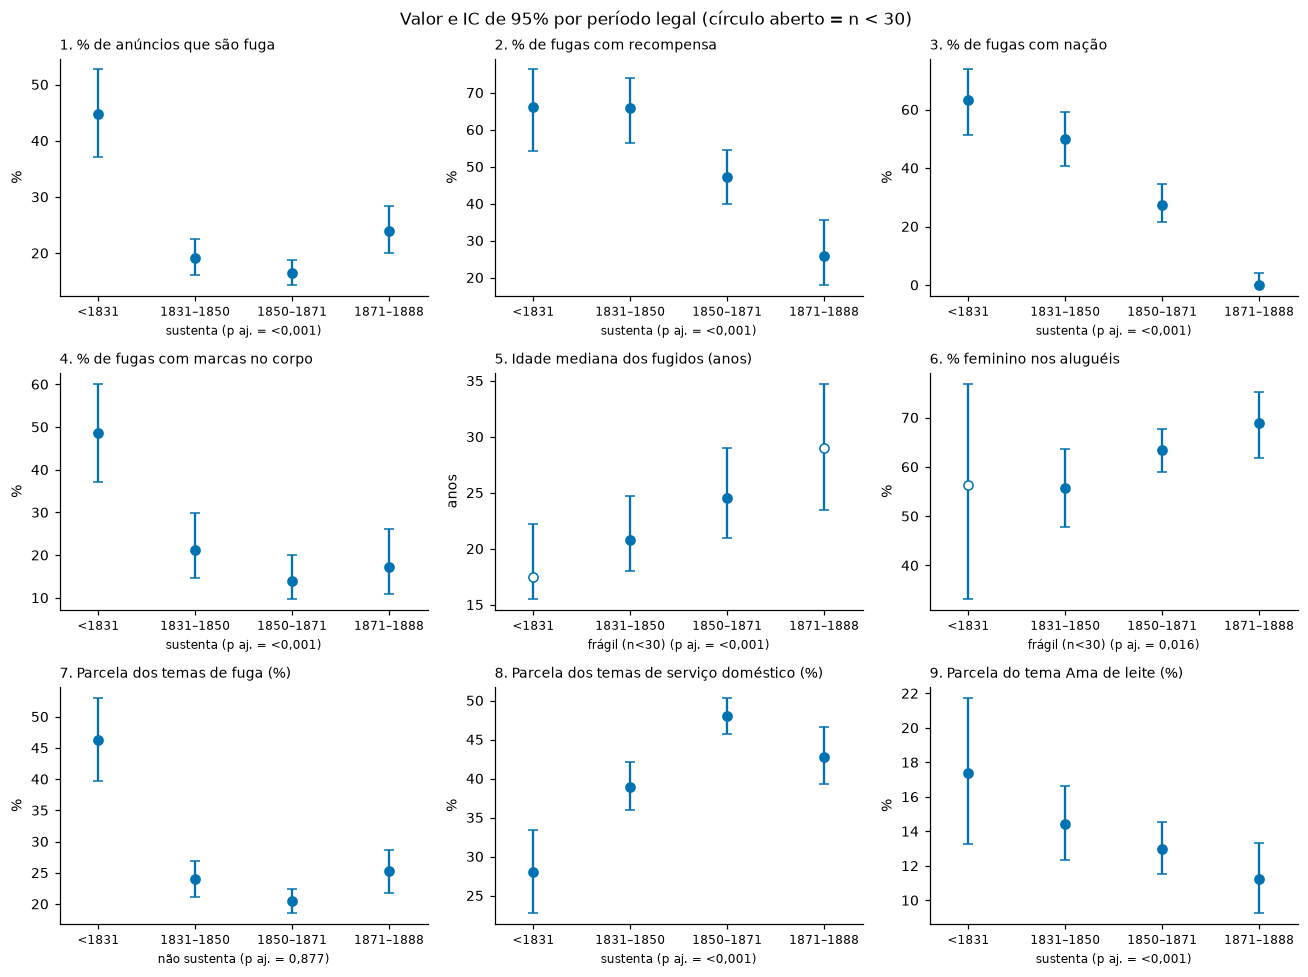

In [5]:
fig, eixos = plt.subplots(3, 3, figsize=(12, 9))
for ax, n in zip(eixos.ravel(), nomes_ok):
    r = RES[n]
    ax.set_title(n, fontsize=9, loc="left")
    if r is None:
        ax.text(0.5, 0.5, "tema ausente", ha="center", va="center", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        continue
    for i, p in enumerate(PERIODOS):
        c = r["por"][p]
        if c["n"] == 0:
            continue
        ax.errorbar(i, c["valor"], yerr=[[max(c["valor"] - c["baixo"], 0)], [max(c["alto"] - c["valor"], 0)]], fmt="o", color=COR,
                    ecolor=COR, capsize=3, mfc="white" if c["n"] < MIN_N else COR)
    ax.set_xticks(range(len(PERIODOS)))
    ax.set_xticklabels([p.replace("antes de ", "<") for p in PERIODOS], fontsize=8)
    ax.set_ylabel(r["unidade"]); ax.set_xlim(-0.4, len(PERIODOS) - 0.6)
    ax.set_xlabel(f"{veredito(r)} (p aj. = {pf(r.get('padj'))})", fontsize=8)
fig.suptitle("Valor e IC de 95% por período legal (círculo aberto = n < 30)")
fig.tight_layout(); plt.show()

**Como ler os gráficos:** o ponto é o valor e a barra é o intervalo de 95%; círculo aberto indica menos de 30 anúncios. Quando as barras de dois períodos **não se tocam**, a diferença entre eles é clara (por exemplo a recompensa em 1831–1850 contra 1850–1871, ou a nação em 1850–1871 contra 1871–1888). Quando se tocam, a diferença pode ser acaso. **Os intervalos são um pouco otimistas:** o mesmo aviso pode ser repetido em vários dias e anúncios do mesmo dono não são independentes.

## 5. O que sustenta e o que não sustenta
**Sustenta** = p ajustado < 0,05 **e** o IC da diferença (último − primeiro) não contém zero; **frágil** = o primeiro ou o último
período tem n < 30; **não sustenta** = o restante. "Não sustenta" não prova que não houve mudança: pode ser só que faltem anúncios.

**O que sustenta:** a **queda da recompensa e da nação citada nas fugas depois de 1850** e a **queda das marcas no corpo depois de antes de 1831** são as mais firmes: diferenças grandes e intervalos longe de zero. O **serviço doméstico** (temas somados) **cresce até 1850–1871** e a **ama de leite** cai pouco.

**O que NÃO sustenta (ou sustenta só em parte):**

- **Idade mediana e % feminino nos aluguéis** têm um extremo com menos de 30 anúncios: ficam como **pista**.
- **A parcela dos temas de fuga** não mostra tendência contínua: é uma **queda no primeiro salto** e depois estabilidade.
- **A "ama de leite" vale só para este modelo de temas.** O bootstrap usa o modelo fixo e não mede a instabilidade do LDA; no caderno `equilibrio_periodos`, com períodos do mesmo tamanho, a ama de leite *sobe*. Portanto essa queda **não** deve ir para a apresentação como achado.
- **A parcela de fuga entre os anúncios (medida 1) é mistura da amostra** (o que a busca encontrou em cada período), e o último período está inflado pelas páginas de 1887, que são só de fuga.

**Próximo passo:** repetir estas medidas **ajustando pela mistura de tipos** e **só com o Jornal do Commercio**, para ver quais tendências sobrevivem às duas confusões.